# 06 — Métricas: cómo se mide si un clasificador funciona

**Objetivo:** entender y poder justificar las métricas de la tesis. Al
terminar deberías poder explicar:
- la **matriz de confusión** y las métricas que salen de ella: sensibilidad,
  especificidad, valores predictivos, exactitud, exactitud balanceada y F1;
- por qué la **exactitud** engaña cuando las clases están desbalanceadas;
- qué es el **umbral** y cómo cambia la sensibilidad y la especificidad;
- qué son la **curva ROC** y el **AUC**, y por qué el AUC es la métrica principal;
- por qué los valores predictivos dependen de la **prevalencia**.

La buena noticia: casi todo esto ya lo conocés de la clínica. **Un
clasificador es un test diagnóstico.** Sensibilidad, especificidad, valor
predictivo y curva ROC significan exactamente lo mismo que para una troponina
o un dímero D.

In [44]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.paths import OUT_DIR

SEMILLA = 42
NO_FEATURES = ["file_id", "label", "label_binary"]

## 1. El clasificador como test diagnóstico

- **Positivo** = patológico (clase 1). **Negativo** = normal (clase 0).
- El modelo no responde "sí" o "no": devuelve una **probabilidad** de que la
  grabación sea patológica, entre 0 y 1. Como un análisis que da un valor
  numérico (por ejemplo, una troponina en ng/L).
- Para decidir "positivo" o "negativo" hace falta un **umbral** (*cutoff*),
  igual que el valor de corte de un análisis. Por defecto se usa 0,5.

## 2. Conseguir predicciones

Necesitamos un modelo que dé probabilidades. Usamos el más simple de la
tesis, la **regresión logística**, sobre las features de los sonidos
**pulmonares**. Cómo funciona por dentro lo vemos en la notebook 08.

Para que las probabilidades sean honestas, cada grabación tiene que ser
evaluada por un modelo que **no la vio** al entrenar. Usamos validación
cruzada de 5 particiones: se entrena con 4/5 de los datos, se predice el 1/5
restante, y se repite hasta que todas las grabaciones tienen su predicción
"fuera de la partición" (*out-of-fold*). Los detalles de la validación (y la
diferencia entre partir por grabación o por caso) son el tema de la notebook 07.

In [45]:
def predicciones(subset):
    """Probabilidad out-of-fold de 'patológico' para cada grabación."""
    df = pd.read_csv(OUT_DIR / f"{subset.lower()}_features.csv")
    X, y = df.drop(columns=NO_FEATURES), df["label_binary"].values
    modelo = make_pipeline(StandardScaler(),
                           LogisticRegression(max_iter=2000, class_weight="balanced"))
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    prob = cross_val_predict(modelo, X, y, cv=cv, method="predict_proba")[:, 1]
    return y, prob, df["label"].values


y, prob, tipos = predicciones("LS")
print(f"{len(y)} grabaciones: {int((y == 1).sum())} patológicas, {int((y == 0).sum())} normales")
print("Primeras 8 probabilidades:", np.round(prob[:8], 2))

50 grabaciones: 38 patológicas, 12 normales
Primeras 8 probabilidades: [0.14 0.01 0.   0.   0.13 0.01 0.95 0.99]


Así se ven las probabilidades de cada clase. Lo ideal sería que todos los
normales quedaran cerca de 0 y todos los patológicos cerca de 1:

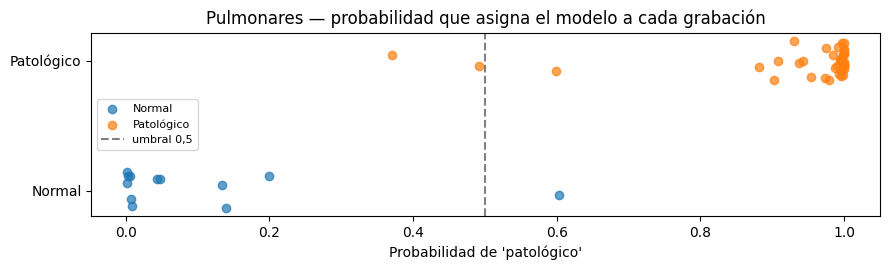

In [46]:
fig, ax = plt.subplots(figsize=(9, 2.8))
for clase, color, nombre in [(0, "tab:blue", "Normal"), (1, "tab:orange", "Patológico")]:
    v = prob[y == clase]
    ax.scatter(v, np.full(len(v), clase) + np.random.uniform(-0.15, 0.15, len(v)),
               c=color, alpha=0.7, label=nombre)
ax.axvline(0.5, color="gray", ls="--", label="umbral 0,5")
ax.set(yticks=[0, 1], yticklabels=["Normal", "Patológico"], xlabel="Probabilidad de 'patológico'",
       title="Pulmonares — probabilidad que asigna el modelo a cada grabación")
ax.legend(loc="center left", fontsize=8)
fig.tight_layout()

## 3. La matriz de confusión

Con el umbral de 0,5, cada grabación cae en una de cuatro casillas, como en la
tabla 2×2 de cualquier test diagnóstico:

| | Predicho normal | Predicho patológico |
|---|---|---|
| **Realmente normal** | Verdadero negativo (VN) | Falso positivo (FP) |
| **Realmente patológico** | Falso negativo (FN) | Verdadero positivo (VP) |

In [47]:
UMBRAL = 0.5
pred = (prob >= UMBRAL).astype(int)
vn, fp, fn, vp = confusion_matrix(y, pred).ravel()
print(pd.DataFrame([[vn, fp], [fn, vp]], index=["Realmente normal", "Realmente patológico"],
                   columns=["Predicho normal", "Predicho patológico"]).to_string())

                      Predicho normal  Predicho patológico
Realmente normal                   11                    1
Realmente patológico                2                   36


## 4. Las métricas que salen de la matriz

| Métrica | Fórmula | Pregunta que responde |
|---|---|---|
| **Sensibilidad** (*recall*) | VP / (VP + FN) | De los patológicos, ¿cuántos detecta? |
| **Especificidad** | VN / (VN + FP) | De los normales, ¿cuántos reconoce como normales? |
| **Valor predictivo positivo** (*precision*) | VP / (VP + FP) | Si dice "patológico", ¿qué tan seguido acierta? |
| **Valor predictivo negativo** | VN / (VN + FN) | Si dice "normal", ¿qué tan seguido acierta? |
| **Exactitud** (*accuracy*) | (VP + VN) / total | ¿Qué fracción del total clasifica bien? |
| **Exactitud balanceada** | (sensibilidad + especificidad) / 2 | Promedio de los aciertos en cada clase |
| **F1** | 2 · VPP · sens / (VPP + sens) | Compromiso entre VPP y sensibilidad (de la clase positiva) |
| **F1 macro** | promedio del F1 de cada clase | Igual, pero dándole el mismo peso a las dos clases |

Los nombres en inglés (*recall*, *precision*) son los que vas a ver en
scikit-learn y en los papers de aprendizaje automático.

In [48]:
def metricas(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = vp / (vp + fn)
    esp = vn / (vn + fp)
    vpp = vp / (vp + fp) if vp + fp else np.nan
    vpn = vn / (vn + fn) if vn + fn else np.nan
    # Si el modelo nunca predice una clase, su VPP/VPN no existe: el F1 de esa clase vale 0
    f1_pos = 2 * vpp * sens / (vpp + sens) if vp else 0.0
    f1_neg = 2 * vpn * esp / (vpn + esp) if vn else 0.0
    return {"sensibilidad": sens, "especificidad": esp, "VPP": vpp, "VPN": vpn,
            "exactitud": (vp + vn) / len(y), "exactitud balanceada": (sens + esp) / 2,
            "F1 (patológico)": f1_pos, "F1 macro": (f1_pos + f1_neg) / 2}


print(pd.Series(metricas(y, prob)).round(3).to_string())

sensibilidad            0.947
especificidad           0.917
VPP                     0.973
VPN                     0.846
exactitud               0.940
exactitud balanceada    0.932
F1 (patológico)         0.960
F1 macro                0.920


## 5. Por qué no usamos la exactitud (el % de aciertos totales)

**Qué vamos a hacer y para qué.** En esta sección usamos un **ejemplo inventado a propósito**, que no es un modelo de la tesis: una "respuesta de referencia" que **no analiza el sonido** y dice "patológico" para todas las grabaciones. El objetivo es mostrar que la exactitud puede dar un número alto aunque no se distinga nada, y que por eso la tesis usa otras métricas.

**Analogía clínica.** En un servicio donde el 76 % de los pacientes que llegan con dolor de pecho tienen un infarto, un "test" que dice "infarto" a todos, sin mirar nada, acierta el 76 % de las veces. Pero no sirve: no descarta a ningún paciente sano. Ante cualquier test que "acierta el 76 %", la pregunta obligada es: ¿cuánto acertaría diciendo lo mismo a todos?

**Las cuentas, con los pulmonares:** hay 38 grabaciones patológicas y 12 normales. Si se responde "patológico" para las 50:
- acierta las 38 patológicas y se equivoca en las 12 normales;
- aciertos totales: 38 / 50 = **76 %**.

Ahora comparamos esa referencia con el modelo real (la regresión logística), con las mismas métricas:


                      modelo real (regresión logística)  referencia: siempre 'patológico'
sensibilidad                                       0.95                              1.00
especificidad                                      0.92                              0.00
VPP                                                0.97                              0.76
VPN                                                0.85                               NaN
exactitud                                          0.94                              0.76
exactitud balanceada                               0.93                              0.50
F1 (patológico)                                    0.96                              0.86
F1 macro                                           0.92                              0.43
AUC                                                0.99                              0.50


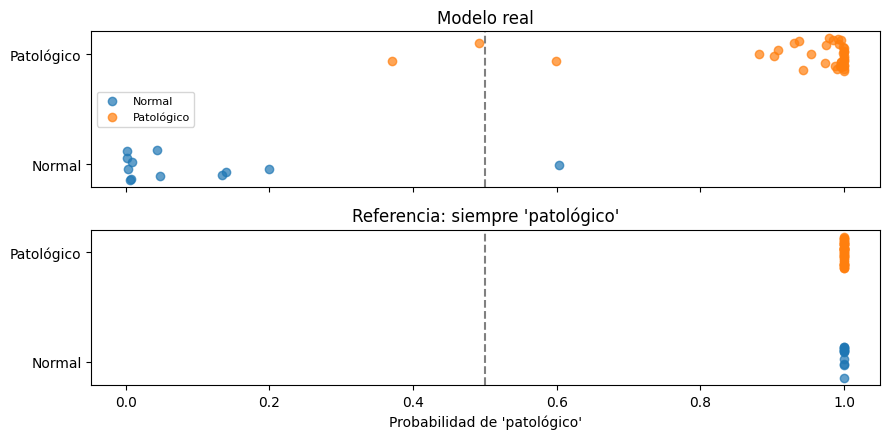

In [49]:
# Referencia: probabilidad 1 de "patológico" para todas las grabaciones (no mira el sonido)
prob_referencia = np.ones(len(y))

comparacion = pd.DataFrame({
    "modelo real (regresión logística)": {**metricas(y, prob), "AUC": roc_auc_score(y, prob)},
    "referencia: siempre 'patológico'": {**metricas(y, prob_referencia), "AUC": roc_auc_score(y, prob_referencia)},
})
print(comparacion.round(2).to_string())

fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
for ax, (nombre, p) in zip(axes, [("Modelo real", prob), ("Referencia: siempre 'patológico'", prob_referencia)]):
    for clase, color, etiqueta in [(0, "tab:blue", "Normal"), (1, "tab:orange", "Patológico")]:
        v = p[y == clase]
        ax.scatter(v, np.full(len(v), clase) + np.random.uniform(-0.15, 0.15, len(v)),
                   c=color, alpha=0.7, label=etiqueta)
    ax.axvline(0.5, color="gray", ls="--")
    ax.set(yticks=[0, 1], yticklabels=["Normal", "Patológico"], title=nombre)
axes[0].legend(loc="center left", fontsize=8)
axes[-1].set_xlabel("Probabilidad de 'patológico'")
fig.tight_layout()


**Cómo leerlo.**
- En el gráfico de arriba (modelo real), los normales quedan a la izquierda del umbral y los patológicos a la derecha: el modelo **distingue**.
- En el de abajo (referencia), **todos** los puntos, normales y patológicos, están amontonados en 1,0: no distingue nada.
- Aun así, la referencia tiene **76 % de exactitud**. Ese número sale alto solo porque hay muchas más grabaciones patológicas que normales.

**Mirando cada grupo por separado, el problema salta a la vista:** la referencia acierta 38 de 38 patológicos (sensibilidad 1,0) y 0 de 12 normales (especificidad 0). Las métricas que miran los dos grupos por separado, o que comparan pares, la desenmascaran:
- **especificidad** = 0;
- **exactitud balanceada** = 0,5 (lo mismo que el azar);
- **F1 macro** ≈ 0,43;
- **AUC** = 0,5 (lo mismo que el azar).

En cambio, el **F1 de la clase patológica** también se deja engañar (~0,86): como los patológicos son mayoría, decir siempre "patológico" le da un VPP alto y una sensibilidad perfecta. Por eso, cuando la tesis diga "F1", conviene que sea el **F1 macro**, que promedia las dos clases.

**Conclusión:** la exactitud mezcla los dos grupos, y como uno es mucho más grande, tapa lo que pasa con el otro. Por eso no es la métrica principal de la tesis.

> *Frase para la tesis:* "Como el 76 % de los registros pulmonares (82 % de los cardíacos) es patológico, un clasificador que no discriminara nada alcanzaría igual esa exactitud. Por eso no se usa la exactitud como métrica principal, sino métricas que evalúan cada clase por separado (sensibilidad, especificidad, exactitud balanceada, F1 macro) o la capacidad de ordenar los registros (AUC)."

En la jerga se le llama **clasificador de referencia** o *dummy* (scikit-learn lo trae como `DummyClassifier`): es la línea de base mínima que cualquier modelo tiene que superar.


## 6. El umbral: sensibilidad vs. especificidad

Igual que con el valor de corte de un análisis: si bajás el umbral, el test
dice "positivo" más fácil, así que **sube la sensibilidad y baja la
especificidad**. Si lo subís, al revés.

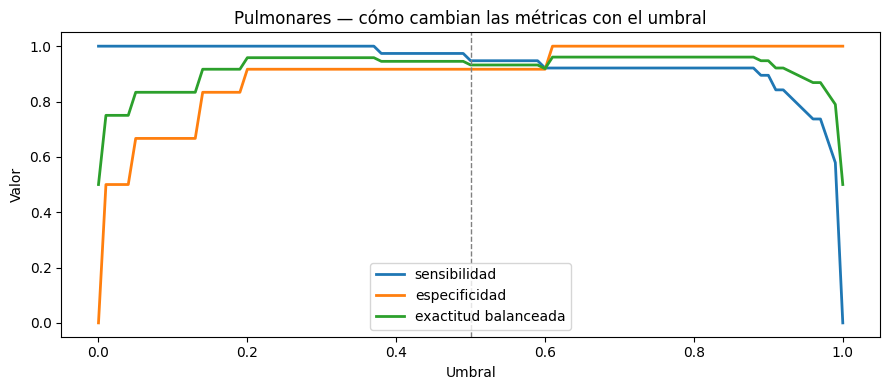

In [50]:
umbrales = np.linspace(0, 1, 101)
curvas = pd.DataFrame([metricas(y, prob, u) for u in umbrales], index=umbrales)

fig, ax = plt.subplots(figsize=(9, 4))
for col in ["sensibilidad", "especificidad", "exactitud balanceada"]:
    ax.plot(umbrales, curvas[col], lw=2, label=col)
ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.set(xlabel="Umbral", ylabel="Valor", title="Pulmonares — cómo cambian las métricas con el umbral")
ax.legend()
fig.tight_layout()

¿Qué umbral elegir? Depende del **uso**. En **tamizaje**, un falso negativo
(una patología que no se detecta) suele ser más grave que un falso positivo
(que se resuelve con otra evaluación), así que se prefiere un umbral bajo,
con alta sensibilidad. Esa elección es clínica, no estadística.

## 7. La curva ROC y el AUC

Cada umbral da un par (sensibilidad, especificidad). Si los graficamos todos,
con **1 − especificidad** en el eje x (la tasa de falsos positivos) y la
**sensibilidad** en el eje y, obtenemos la **curva ROC**: la misma que se usa
para comparar marcadores de laboratorio.

- Un test perfecto sube derecho hasta arriba a la izquierda (sensibilidad 1
  con especificidad 1).
- Un test que no sirve sigue la diagonal (como tirar una moneda).
- El **AUC** (área bajo la curva) resume la curva en un número entre 0,5
  (azar) y 1 (perfecto).

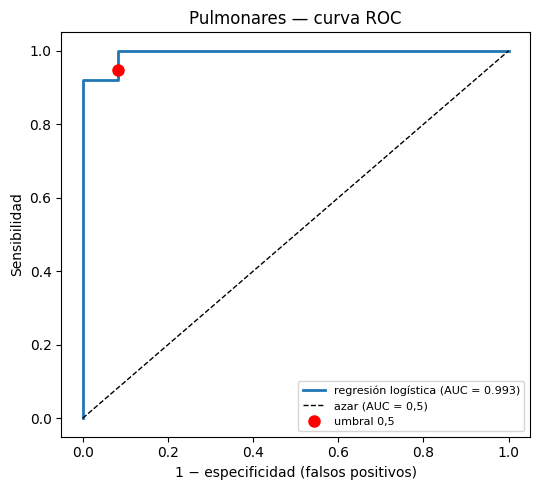

In [51]:
fpr, tpr, _ = roc_curve(y, prob)
auc = roc_auc_score(y, prob)
pred05 = (prob >= 0.5).astype(int)
punto = metricas(y, prob, 0.5)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, lw=2, label=f"regresión logística (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="azar (AUC = 0,5)")
ax.plot(1 - punto["especificidad"], punto["sensibilidad"], "ro", ms=8, label="umbral 0,5")
ax.set(xlabel="1 − especificidad (falsos positivos)", ylabel="Sensibilidad",
       title="Pulmonares — curva ROC")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()

Fijate en la forma "escalonada": cada escalón horizontal es un normal y cada
escalón vertical, un patológico. Con 12 normales, cada uno mueve la
especificidad 1/12 ≈ 8 puntos. Con tan pocos casos las curvas son toscas, y
por eso la tesis reporta intervalos de confianza.

### Qué significa el AUC, de verdad

El AUC tiene una interpretación muy concreta: **si tomás al azar una
grabación patológica y una normal, es la probabilidad de que el modelo le dé
más probabilidad de "patológico" a la patológica.** Lo comprobamos contando
todos los pares posibles:

In [52]:
pat, nor = prob[y == 1], prob[y == 0]
bien_ordenados = (pat[:, None] > nor[None, :]).sum() + 0.5 * (pat[:, None] == nor[None, :]).sum()
print(f"Pares patológico-normal: {len(pat)} × {len(nor)} = {len(pat) * len(nor)}")
print(f"Pares bien ordenados: {bien_ordenados:.0f}  ->  proporción = {bien_ordenados / (len(pat) * len(nor)):.3f}")
print(f"AUC calculado por sklearn: {auc:.3f}")

Pares patológico-normal: 38 × 12 = 456
Pares bien ordenados: 453  ->  proporción = 0.993
AUC calculado por sklearn: 0.993


Son el mismo número.

### AUC vs. sensibilidad y especificidad: dos preguntas distintas

Puede parecer una contradicción decir que el AUC "no depende del umbral" y a la vez que hay que reportar sensibilidad y especificidad "en el umbral elegido". No lo es, porque responden preguntas distintas:

| | Pregunta que responde | ¿Depende del umbral? |
|---|---|---|
| **AUC** | ¿Qué tan bien **ordena** el modelo las grabaciones? | No: resume la curva ROC completa, todos los umbrales a la vez, sin elegir ninguno |
| **Sensibilidad y especificidad** | ¿Qué tan bien **decide** el modelo con el corte que vamos a usar? | Sí: se calculan en un umbral concreto |

**Analogía con la troponina.** El AUC de la troponina es una propiedad del marcador: qué tan bien separa infartos de no infartos en general. Pero en la guardia no se usa "la troponina en general": se usa un **valor de corte**, y con ese corte hay una sensibilidad y una especificidad concretas. Con el mismo marcador (el mismo AUC), un laboratorio que usa un corte alto tiene más especificidad y menos sensibilidad que otro que usa un corte bajo.

Con dos modelos pasa lo mismo: pueden **ordenar** igual de bien (mismo AUC) y, sin embargo, con el umbral de 0,5 uno puede tener buena especificidad y el otro mala, si sus probabilidades están "corridas" (la sección 11 muestra un caso real con el random forest).

Por eso:
- el **AUC** sirve para comparar la capacidad de discriminar de los modelos;
- la **sensibilidad y la especificidad en el umbral elegido** dicen cómo funcionaría cada modelo en la práctica;
- y con pocos casos el AUC es muy variable, así que necesita **intervalo de confianza**.

Una propiedad más del AUC: **no depende de la proporción de clases**, porque compara pares patológico-normal en lugar de contar aciertos sobre el total.

*Sobre elegir el "mejor umbral" para cada modelo:* si se elige mirando los mismos datos con los que se evalúa, el resultado sale optimista (como con los filtros en la notebook 02). Lo correcto es elegirlo dentro de la validación, solo con los datos de entrenamiento, o usar 0,5 para todos y decirlo explícitamente.


## 8. La curva precisión-sensibilidad (PR)

Grafica el **VPP** (*precision*) contra la **sensibilidad** (*recall*) para
todos los umbrales. Su área (*average precision*, AP) se usa cuando la clase
positiva es **rara**, porque se concentra en qué tan bien se encuentra esa
clase minoritaria.

Ojo con un detalle de este dataset: acá la clase positiva (patológico) es la
**mayoritaria** (76 %). Un clasificador al azar ya tiene un VPP de 0,76, así
que un AP alto impresiona menos. Si se quiere usar, tiene más sentido
calcularla tomando **normal** como la clase "a encontrar":

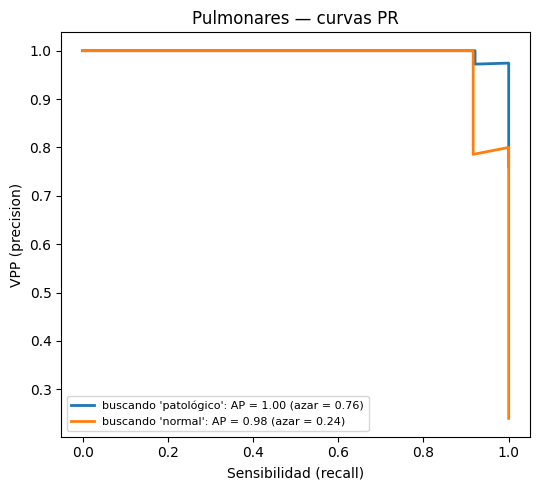

In [53]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for positiva, p, nombre in [(1, prob, "patológico"), (0, 1 - prob, "normal")]:
    yy = (y == positiva).astype(int)
    precision, recall, _ = precision_recall_curve(yy, p)
    ap = average_precision_score(yy, p)
    ax.plot(recall, precision, lw=2, label=f"buscando '{nombre}': AP = {ap:.2f} (azar = {yy.mean():.2f})")
ax.set(xlabel="Sensibilidad (recall)", ylabel="VPP (precision)", title="Pulmonares — curvas PR")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()

## 9. Los valores predictivos dependen de la prevalencia

Sensibilidad y especificidad son propiedades del test. El **VPP y el VPN, no**:
dependen de cuántos enfermos hay en la población donde se usa. En este
dataset el 76 % es patológico, pero en un consultorio de atención primaria
la mayoría de las auscultaciones son normales. Con el teorema de Bayes
podemos estimar el VPP que tendría **el mismo** test en otras prevalencias:

In [54]:
s, e = punto["sensibilidad"], punto["especificidad"]
filas = []
for prev in [0.76, 0.30, 0.10, 0.05]:
    vpp = s * prev / (s * prev + (1 - e) * (1 - prev))
    vpn = e * (1 - prev) / (e * (1 - prev) + (1 - s) * prev)
    filas.append({"prevalencia de patológico": prev, "VPP": vpp, "VPN": vpn})
print(f"Sensibilidad = {s:.2f}, especificidad = {e:.2f} (umbral 0,5)")
print(pd.DataFrame(filas).round(2).to_string(index=False))

Sensibilidad = 0.95, especificidad = 0.92 (umbral 0,5)
 prevalencia de patológico  VPP  VPN
                      0.76 0.97 0.85
                      0.30 0.83 0.98
                      0.10 0.56 0.99
                      0.05 0.37 1.00


Con la misma sensibilidad y especificidad, el VPP cae mucho cuando la
patología es poco frecuente. Es la limitación que menciona la tesis en 8.6:
las métricas que dependen de la prevalencia **no se trasladan** a la clínica.
AUC, sensibilidad y especificidad sí son comparables entre poblaciones.

## 10. Cardíacos, para comparar

Lo mismo con los sonidos cardíacos (9 normales, 41 patológicos):

AUC cardíacos: 0.753
sensibilidad            0.854
especificidad           0.556
VPP                     0.897
VPN                     0.455
exactitud               0.800
exactitud balanceada    0.705
F1 (patológico)         0.875
F1 macro                0.688


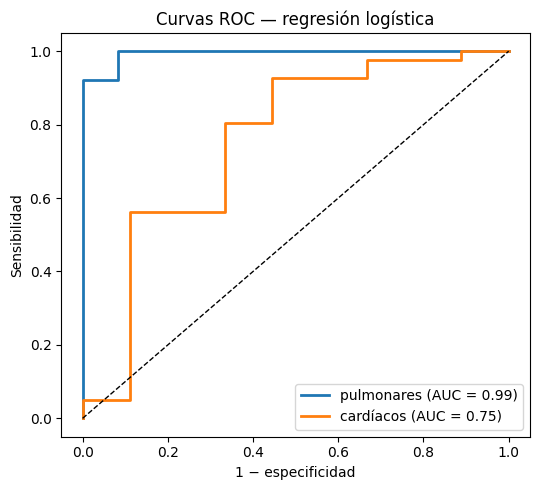

In [55]:
y_hs, prob_hs, _ = predicciones("HS")
fpr_hs, tpr_hs, _ = roc_curve(y_hs, prob_hs)
print(f"AUC cardíacos: {roc_auc_score(y_hs, prob_hs):.3f}")
print(pd.Series(metricas(y_hs, prob_hs)).round(3).to_string())

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, lw=2, label=f"pulmonares (AUC = {auc:.2f})")
ax.plot(fpr_hs, tpr_hs, lw=2, label=f"cardíacos (AUC = {roc_auc_score(y_hs, prob_hs):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="1 − especificidad", ylabel="Sensibilidad", title="Curvas ROC — regresión logística")
ax.legend(loc="lower right")
fig.tight_layout()

## 11. Las mismas métricas para todos los modelos

Usamos la regresión logística como ejemplo, pero las métricas se definen igual para cualquier modelo: solo necesitan que el modelo dé, para cada grabación, una probabilidad (o un puntaje) de "patológico". Lo que cambia de un modelo a otro son los **valores**. Comparar modelos es justamente eso: aplicar las **mismas** métricas, con la **misma** validación, a todos.

Probamos cuatro modelos de la tesis sobre los mismos datos pulmonares (sin ajustar nada; la comparación en serio es la notebook 11 del plan):


In [56]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

df_ls = pd.read_csv(OUT_DIR / "ls_features.csv")
X_ls, y_ls = df_ls.drop(columns=NO_FEATURES), df_ls["label_binary"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
modelos = {
    "Regresión logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEMILLA),
    "Random forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEMILLA),
    "SVM-RBF": SVC(probability=True, class_weight="balanced", random_state=SEMILLA),
}

probs_modelos, filas = {}, []
for nombre, modelo in modelos.items():
    p = cross_val_predict(make_pipeline(StandardScaler(), modelo), X_ls, y_ls, cv=cv, method="predict_proba")[:, 1]
    probs_modelos[nombre] = p
    m = metricas(y_ls, p)
    filas.append({"modelo": nombre, "AUC": roc_auc_score(y_ls, p), "sensibilidad": m["sensibilidad"],
                  "especificidad": m["especificidad"], "F1 macro": m["F1 macro"],
                  "probabilidades distintas": len(np.unique(np.round(p, 6)))})
print(pd.DataFrame(filas).round(2).to_string(index=False))


             modelo  AUC  sensibilidad  especificidad  F1 macro  probabilidades distintas
Regresión logística 0.99          0.95           0.92      0.92                        50
  Árbol de decisión 0.81          0.95           0.67      0.83                         2
      Random forest 0.94          1.00           0.58      0.84                        43
            SVM-RBF 0.98          0.97           0.83      0.92                        50


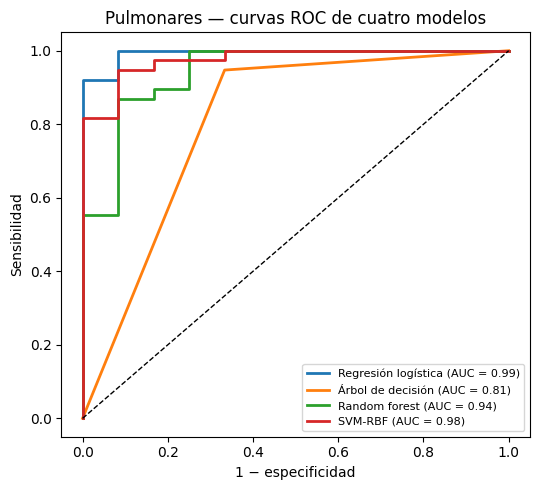

In [57]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for nombre, p in probs_modelos.items():
    fpr_m, tpr_m, _ = roc_curve(y_ls, p)
    ax.plot(fpr_m, tpr_m, lw=2, label=f"{nombre} (AUC = {roc_auc_score(y_ls, p):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="1 − especificidad", ylabel="Sensibilidad", title="Pulmonares — curvas ROC de cuatro modelos")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()


Dos matices que aparecen al comparar modelos:

**1. No todos los modelos dan probabilidades "finas".** Mirá la columna "probabilidades distintas": el árbol de decisión da muy pocos valores. Un árbol ubica cada grabación en una "hoja", y todas las de la misma hoja reciben la misma probabilidad. Por eso su curva ROC tiene muy pocos escalones y su AUC queda limitado. La regresión logística y el SVM dan un valor distinto para cada grabación.

**2. El AUC y el umbral de 0,5 pueden contar historias distintas.** El random forest tiene un AUC alto (ordena bastante bien) pero una especificidad baja con umbral 0,5. Sus "probabilidades" son la proporción de árboles que votan "patológico"; como la mayoría de las grabaciones son patológicas, quedan corridas hacia arriba. El modelo **ordena** bien, pero el corte en 0,5 queda mal ubicado para él. Es la pregunta 6 de esta notebook: el AUC solo no alcanza.

**Para la tesis:** las mismas métricas y la misma validación para todos los modelos. El AUC compara qué tan bien ordena cada uno; la sensibilidad y la especificidad en el umbral elegido muestran cómo funciona en la práctica. Un modelo con buen AUC y mala especificidad no es una contradicción: es una señal de que su umbral no está bien calibrado.


## 12. ¿Cómo justificar las métricas en la tesis?

Un párrafo posible, para adaptar:

> *Dado el desbalance de clases, no se usa la exactitud como métrica
> principal: un clasificador que predijera siempre la clase mayoritaria
> alcanzaría 76–82 % de exactitud sin discriminar. Se adopta como métrica
> principal el área bajo la curva ROC (AUC), que mide la capacidad del modelo
> de ordenar correctamente un registro patológico por encima de uno normal,
> independientemente del umbral y de la proporción de clases. Como el AUC no
> describe el desempeño en un punto de corte concreto, se reportan además la
> sensibilidad y la especificidad en el umbral de 0,5, la exactitud
> balanceada y el F1 macropromediado, que pondera por igual ambas clases. Los
> valores predictivos se informan con la advertencia de que dependen de la
> prevalencia, que en este conjunto no refleja la de la práctica clínica.*

## 13. Tu turno

Cambiá el umbral y mirá cómo se mueven las métricas. ¿Qué umbral elegirías
para un tamizaje, donde no querés perder patologías? ¿Cuánto especificidad
pagás por eso?

In [58]:
UMBRAL_ELEGIDO = 0.3

print(pd.Series(metricas(y, prob, UMBRAL_ELEGIDO)).round(3).to_string())
vn, fp, fn, vp = confusion_matrix(y, (prob >= UMBRAL_ELEGIDO).astype(int)).ravel()
print(f"\nVN={vn}  FP={fp}  FN={fn}  VP={vp}")
print("Patológicos no detectados (FN):", sorted(tipos[(y == 1) & (prob < UMBRAL_ELEGIDO)]))

sensibilidad            1.000
especificidad           0.917
VPP                     0.974
VPN                     1.000
exactitud               0.980
exactitud balanceada    0.958
F1 (patológico)         0.987
F1 macro                0.972

VN=11  FP=1  FN=0  VP=38
Patológicos no detectados (FN): []


## Preguntas de control

1. Si el modelo es un test diagnóstico, ¿qué es el "positivo", qué es el
   umbral y qué son las cuatro casillas de la matriz de confusión?
2. Definí sensibilidad, especificidad, VPP y VPN. ¿Cuáles dependen de la
   prevalencia?
3. ¿Por qué el clasificador que dice siempre "patológico" tiene 76 % de
   exactitud? ¿Qué métricas lo "desenmascaran"?
4. ¿Qué pasa con la sensibilidad y la especificidad al bajar el umbral? ¿Qué
   umbral preferirías en un tamizaje y por qué?
5. ¿Qué significa un AUC de 0,9 en términos de pares de grabaciones? ¿Por qué
   el AUC no depende del umbral ni de la proporción de clases?
6. Si el AUC tiene tantas ventajas, ¿por qué no alcanza con reportar solo el AUC?
7. ¿Por qué en este dataset la curva PR para "patológico" impresiona menos
   que en un problema donde la patología es rara?

## Respuestas a las preguntas de control

*(Intentá responder antes de leer.)*

**1. El modelo como test diagnóstico.**
El positivo es "patológico". El modelo da una probabilidad, como un análisis
da un valor numérico; el umbral es el valor de corte (0,5 por defecto) a
partir del cual decimos "positivo". Las casillas: **VP** (patológico
detectado), **FN** (patológico que se escapa), **VN** (normal reconocido) y
**FP** (normal que el modelo marca como patológico). En pulmonares, con
umbral 0,5: 36 VP, 2 FN, 11 VN y 1 FP.

**2. Las cuatro métricas clínicas.**
Sensibilidad = VP / (VP + FN): de los patológicos, cuántos detecta.
Especificidad = VN / (VN + FP): de los normales, cuántos reconoce. VPP =
VP / (VP + FP): si dice "patológico", cuántas veces acierta. VPN =
VN / (VN + FN): si dice "normal", cuántas veces acierta. **VPP y VPN
dependen de la prevalencia**; sensibilidad y especificidad no.

**3. El clasificador que dice siempre "patológico".**
Tiene 76 % de exactitud porque el 76 % de las grabaciones pulmonares son
patológicas: acierta todas esas sin mirar nada. Lo desenmascaran la
especificidad (0), la exactitud balanceada (0,5), el F1 macro y el AUC (0,5).
El F1 de la clase patológica, en cambio, también lo engaña (~0,86).

**4. Bajar el umbral.**
Sube la sensibilidad y baja la especificidad: el modelo dice "patológico"
más fácil. En tamizaje conviene un umbral bajo, porque una patología no
detectada suele costar más que un falso positivo que después se descarta.
En pulmonares, bajar a 0,3 lleva la sensibilidad a 1,0 sin perder
especificidad (sigue en 0,92); en otros datos el costo puede ser mayor.

**5. Qué significa un AUC de 0,9.**
Que si tomás al azar una grabación patológica y una normal, en el 90 % de
esos pares el modelo le da más probabilidad de "patológico" a la patológica.
No depende del umbral porque mide el **orden** de las probabilidades, no
dónde se corta; y no depende de la proporción de clases porque compara
**pares** patológico-normal, no cuenta aciertos sobre el total.

**6. Por qué no alcanza con el AUC.**
Porque no dice cómo funciona el modelo en el umbral que se va a usar: dos
modelos con igual AUC pueden tener sensibilidades muy distintas en 0,5. Por
eso se reportan además sensibilidad y especificidad en el umbral elegido. Y
con pocos casos el AUC es muy variable: necesita intervalo de confianza.

**7. La curva PR en este dataset.**
Porque la clase "patológico" es mayoritaria (76 %): un clasificador al azar
ya tiene un VPP de 0,76, así que un AP alto impresiona menos. La curva PR es
más útil cuando la clase a encontrar es rara; acá tiene más sentido mirarla
para "normal" (la minoritaria).